<a href="https://colab.research.google.com/github/Empeno07/week7_distributions.R/blob/main/week7_distributions_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Normal : mean = 75.029 (mu = 75 ) | sd = 8.012 (sigma = 8 )
Binomial : mean = 6.014 (size * prob = 6 )
Poisson : mean = 4.026 (lambda = 4 )


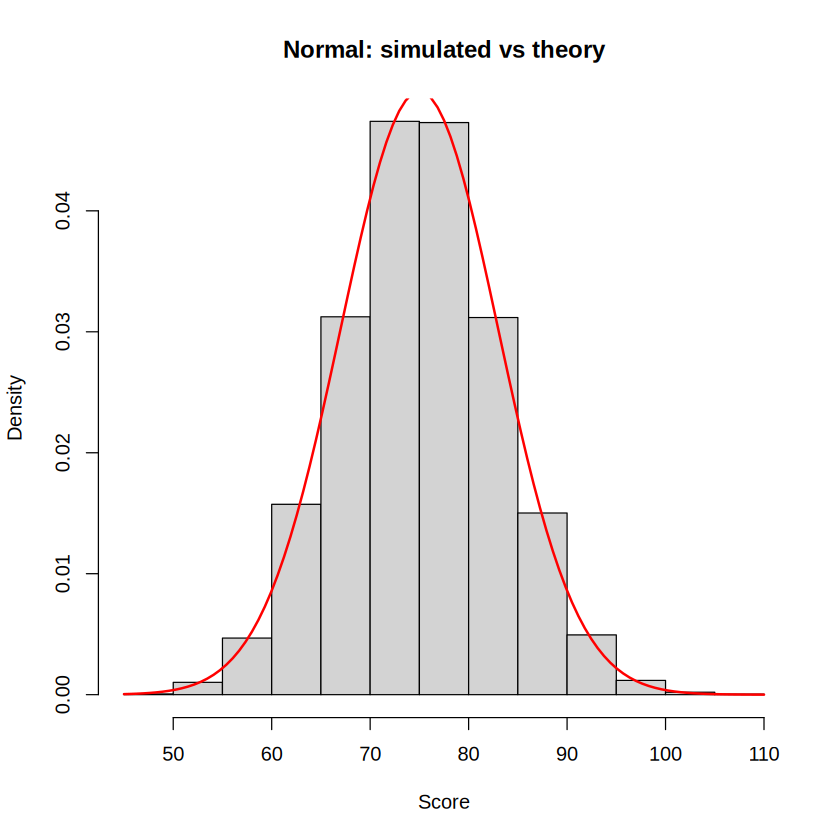

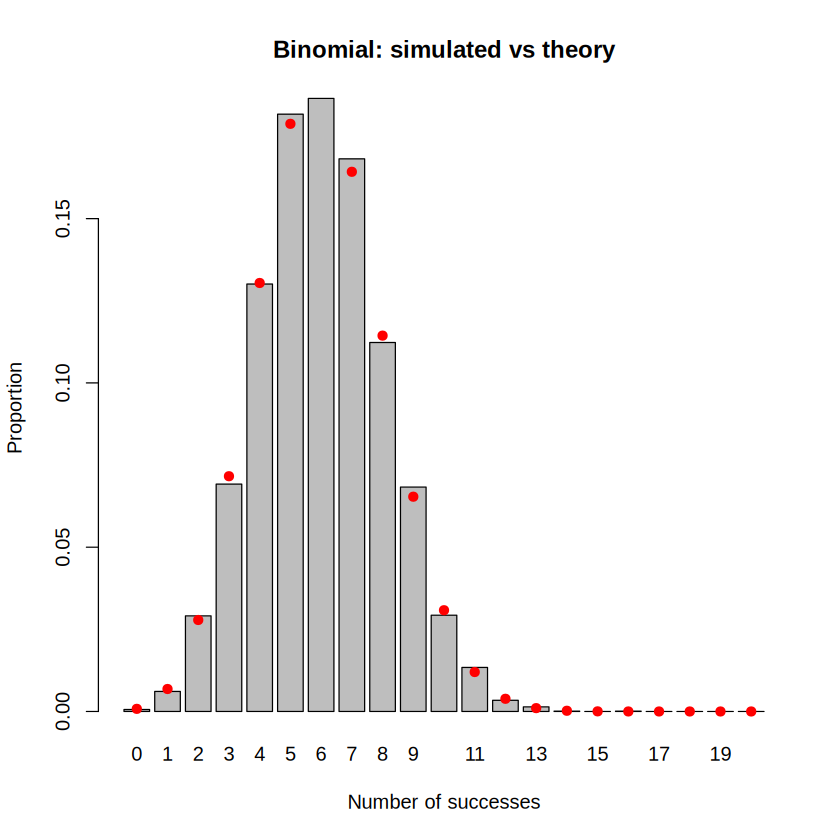

  distribution  event empirical theoretical
1       Normal X > 90    0.0318      0.0304
2     Binomial X >= 8    0.2283      0.2277
3      Poisson X >= 8    0.0515      0.0511


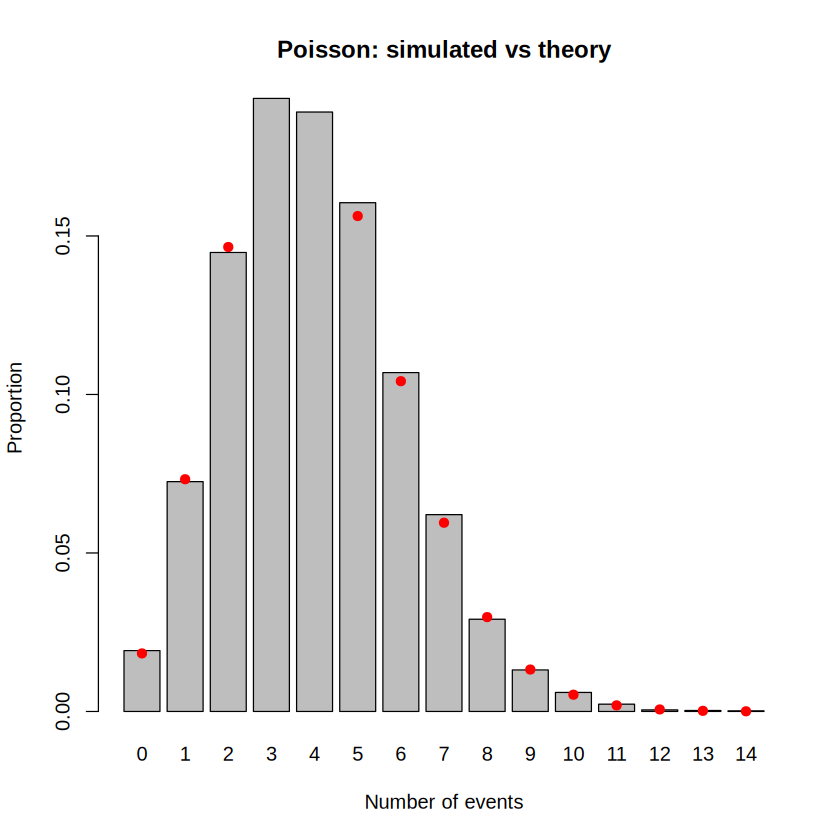

In [24]:
rm(list = ls())

n <- 10000
n_small <- 100
mu <- 75; sigma <- 8
size <- 20; prob <- 0.3
lambda <- 4
cut_norm <- 90; k_binom <- 8; k_pois <- 8

set.seed (2026)

x_norm <- rnorm(n, mean = mu, sd = sigma)
x_binom <- rbinom(n, size = size, prob = prob)
x_pois <- rpois(n, lambda = lambda)

cat("Normal : mean =", round(mean(x_norm), 3), "(mu =", mu, ")", "| sd =", round(sd(x_norm), 3), "(sigma =", sigma, ")\n")
cat("Binomial : mean =", round(mean(x_binom), 3), "(size * prob =", size * prob, ")\n")
cat("Poisson : mean =", round(mean(x_pois), 3), "(lambda =", lambda, ")\n")

hist(x_norm, freq = FALSE, main = "Normal: simulated vs theory",
xlab = "Score", ylab = "Density")
curve(dnorm(x, mu, sigma), add = TRUE, col = "red", lwd = 2)

obs_binom <- table(factor(x_binom, levels = 0:size)) / n
bp_binom <- barplot(obs_binom,
main = "Binomial: simulated vs theory", xlab = "Number of successes", ylab = "Proportion")
points(bp_binom, dbinom(0:size, size, prob), col = "red", pch = 19)

obs_pois <- table(factor(x_pois, levels = 0:max(x_pois))) / n
bp_pois <- barplot(obs_pois, main = "Poisson: simulated vs theory",
xlab = "Number of events", ylab = "Proportion")
points(bp_pois, dpois(0:max(x_pois), lambda), col = "red", pch = 19)

emp <- c(mean(x_norm > cut_norm),
mean(x_binom >= k_binom),
mean(x_pois >= k_pois))

theo <- c(1 - pnorm(cut_norm, mu, sigma),
1 - pbinom(k_binom - 1, size, prob),
1 - ppois(k_pois - 1, lambda))

result <- data.frame( distribution = c("Normal", "Binomial", "Poisson"),
event = c(paste("X >", cut_norm), paste("X >=", k_binom), paste("X >=", k_pois)),
empirical = round(emp, 4),theoretical = round(theo, 4))
print(result)

# INTERPRETATION

# Q1. With n = 10,000 the empirical and theoretical values are very close:
# the Normal tail is 0.0318 vs 0.0304 in theory, the Binomial is 0.2283
# vs 0.2277, and the Poisson is 0.0515 vs 0.0511. My largest gap was only
# 0.0014, well within the 0.01 the guide expects. The red theory curve
# and points also sit on top of the bars, so the simulation agrees with
# the theory, though it is close and not identical.

# Q2. With n = 100 the gap grew from 0.0014 to 0.0211 (Poisson: 0.03
# simulated vs 0.0511 theoretical), so the empirical values moved further
# from the theory. A smaller sample has more random variation, since the
# standard error sqrt(p * (1 - p) / n) is about 10 times larger when n is
# 100 times smaller.

# Q3. set.seed() makes the random draws the same on every run, so anyone
# who reruns my script gets exactly the numbers I reported.
